# 1. Importing all the necessary modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 2. Generating the data

In [2]:
rng = np.random.default_rng(42)   # fixed seed, same data every run
n = 800

fertilizer = rng.uniform(0, 200, n)                 # kg per hectare
rainfall = rng.normal(850, 250, n).clip(250, 1500)  # mm per season
temp = rng.normal(24, 3, n).clip(15, 35)            # average temp, C
soil_ph = rng.normal(6.2, 0.7, n).clip(4.0, 8.0)
irrigation = rng.binomial(1, 0.35, n)               # 1 = irrigated
pests = rng.poisson(2.0, n)                         # pest incidents in season
distance_km = rng.uniform(1, 80, n)                 # distance to market
humidity = np.clip(40 + 0.04 * rainfall + rng.normal(0, 5, n), 20, 100)  # tracks rainfall
plot_size = rng.uniform(0.5, 10, n)                 # irrelevant to yield
farmer_age = rng.integers(22, 75, n)                # irrelevant to yield

# Hidden (true) relationship: nonlinear in fertilizer, rainfall and soil pH
yield_t_ha = (
    2.0
    + 0.035 * fertilizer - 0.00011 * fertilizer**2      # diminishing returns
    - 1.6 * ((rainfall - 850) / 400) ** 2                # best around 850 mm
    - 0.12 * np.maximum(temp - 25, 0)                    # heat stress
    - 1.1 * (soil_ph - 6.5) ** 2                         # best near pH 6.5
    + 0.6 * irrigation
    - 0.25 * pests
    - 0.008 * distance_km
    + rng.normal(0, 0.35, n)                             # noise
)

df = pd.DataFrame({
    "fertilizer_kg_ha": fertilizer.round(1),
    "rainfall_mm": rainfall.round(1),
    "avg_temp_c": temp.round(1),
    "soil_ph": soil_ph.round(2),
    "irrigated": irrigation,
    "pest_incidents": pests,
    "distance_to_market_km": distance_km.round(1),
    "humidity_pct": humidity.round(1),
    "plot_size_ha": plot_size.round(2),
    "farmer_age": farmer_age,
    "yield_t_ha": yield_t_ha.round(3),
})
df.to_csv("farm_yield.csv", index=False)
print(df.shape)
df.head()

(800, 11)


,fertilizer_kg_ha,rainfall_mm,avg_temp_c,soil_ph,irrigated,pest_incidents,distance_to_market_km,humidity_pct,plot_size_ha,farmer_age,yield_t_ha
0,154.8,1282.2,24.1,5.43,0,1,60.0,94.4,9.09,64,1.396
1,87.8,1189.8,23.3,6.03,0,1,30.9,84.0,6.73,50,1.922
2,171.7,913.8,25.0,6.12,1,4,34.8,75.6,6.33,49,3.003
3,139.5,1187.7,24.0,7.32,1,4,27.6,75.7,8.92,60,2.225
4,18.8,853.0,19.6,5.95,0,3,12.9,82.7,1.06,46,1.829


# 3. Explore the data

In [3]:
# Missing values and summary statistics
print("missing values:", df.isna().sum().sum())
df.describe().T.round(2)

missing values: 0


,count,mean,std,min,25%,50%,75%,max
fertilizer_kg_ha,800.0,98.88,58.10,0.20,47.45,98.55,151.22,199.80
rainfall_mm,800.0,845.10,249.92,250.00,681.85,850.85,1004.60,1500.00
avg_temp_c,800.0,23.83,3.02,15.00,21.80,24.00,25.80,32.70
soil_ph,800.0,6.23,0.70,4.20,5.74,6.20,6.72,8.00
irrigated,800.0,0.34,0.47,0.00,0.00,0.00,1.00,1.00
pest_incidents,800.0,1.86,1.36,0.00,1.00,2.00,3.00,7.00
distance_to_market_km,800.0,40.82,22.40,1.10,22.05,41.25,59.50,80.00
humidity_pct,800.0,73.61,11.08,38.60,66.30,73.60,80.90,100.00
plot_size_ha,800.0,5.35,2.75,0.51,2.96,5.48,7.68,9.95
farmer_age,800.0,47.68,15.50,22.00,34.00,48.00,61.00,74.00


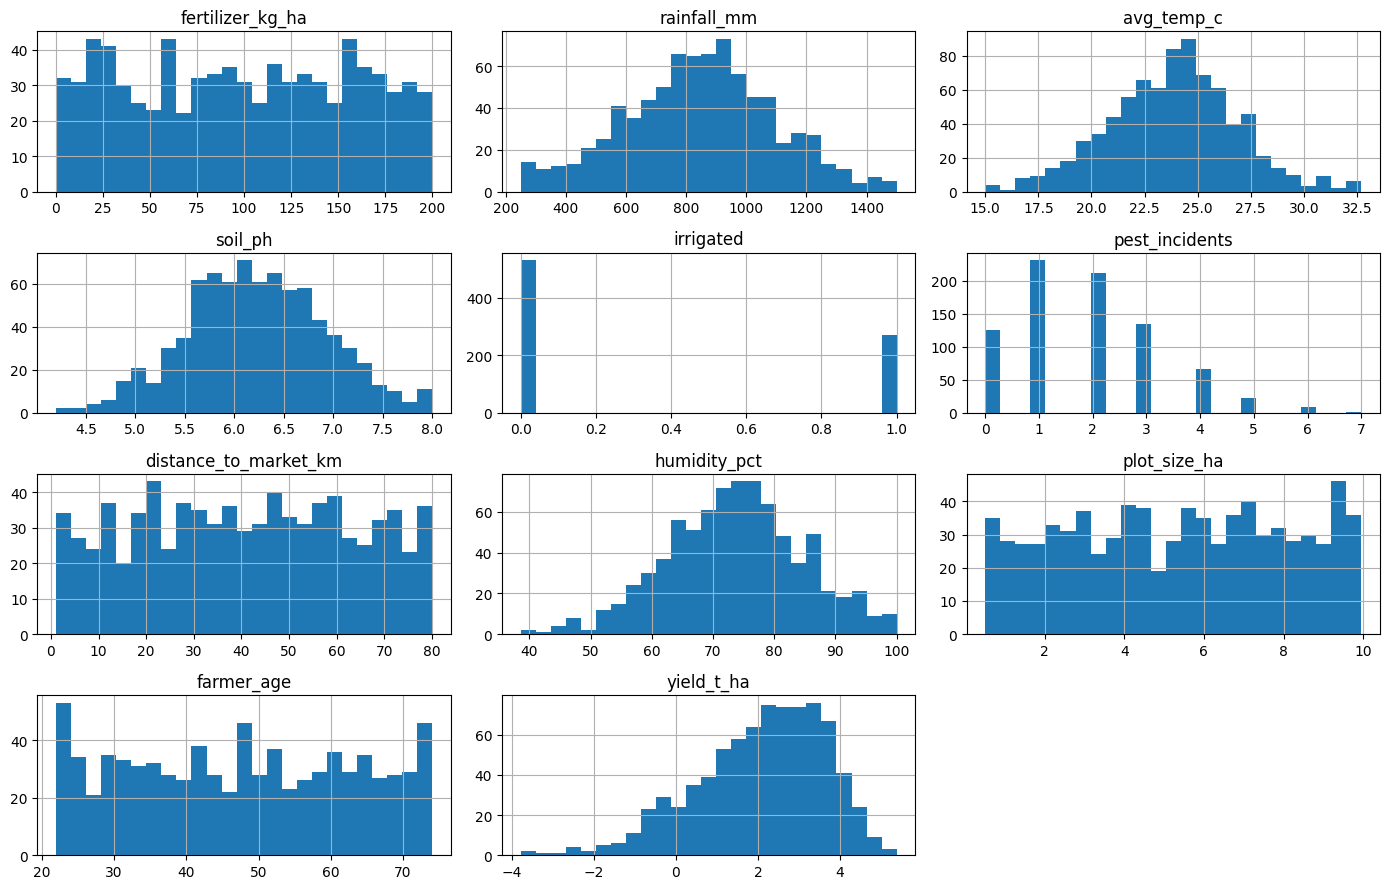

In [4]:
# Histogram of every column
df.hist(figsize=(14, 9), bins=25)
plt.tight_layout()
plt.show()

In [5]:
# Correlation of each feature with yield (straight-line relationships only)
corr = df.corr()
corr["yield_t_ha"].drop("yield_t_ha").sort_values(key=abs, ascending=False).round(3)

fertilizer_kg_ha         0.504
soil_ph                  0.245
pest_incidents          -0.195
irrigated                0.158
distance_to_market_km   -0.129
rainfall_mm              0.113
humidity_pct             0.093
avg_temp_c              -0.088
farmer_age              -0.034
plot_size_ha             0.018
Name: yield_t_ha, dtype: float64

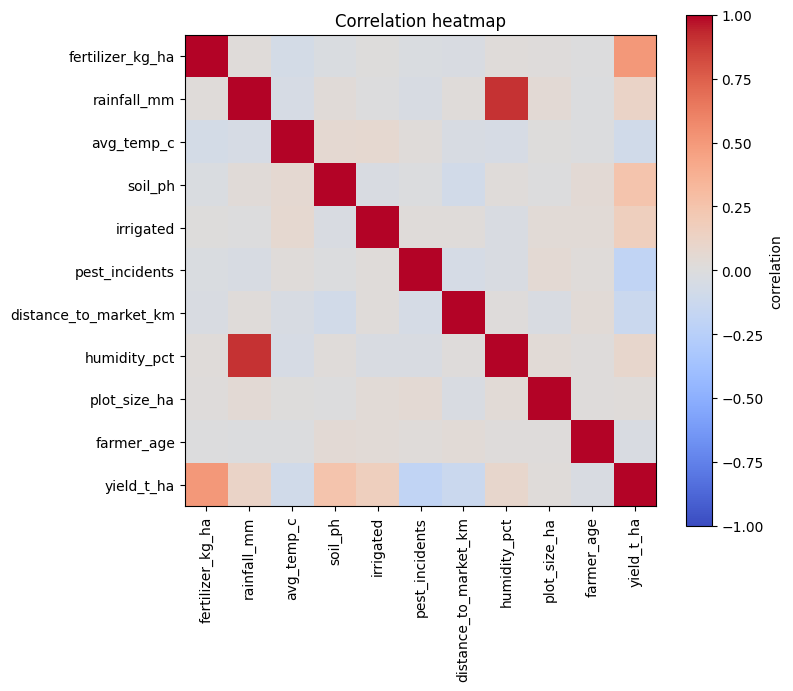

In [6]:
# Correlation heatmap
plt.figure(figsize=(8, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar(label="correlation")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

corr(rainfall, humidity): 0.899


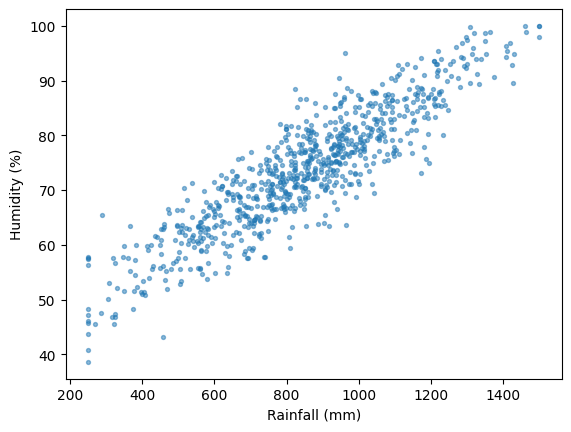

In [7]:
# Humidity vs rainfall: two columns carrying almost the same information
print("corr(rainfall, humidity):", round(corr.loc["rainfall_mm", "humidity_pct"], 3))
plt.scatter(df["rainfall_mm"], df["humidity_pct"], s=8, alpha=0.5)
plt.xlabel("Rainfall (mm)")
plt.ylabel("Humidity (%)")
plt.show()

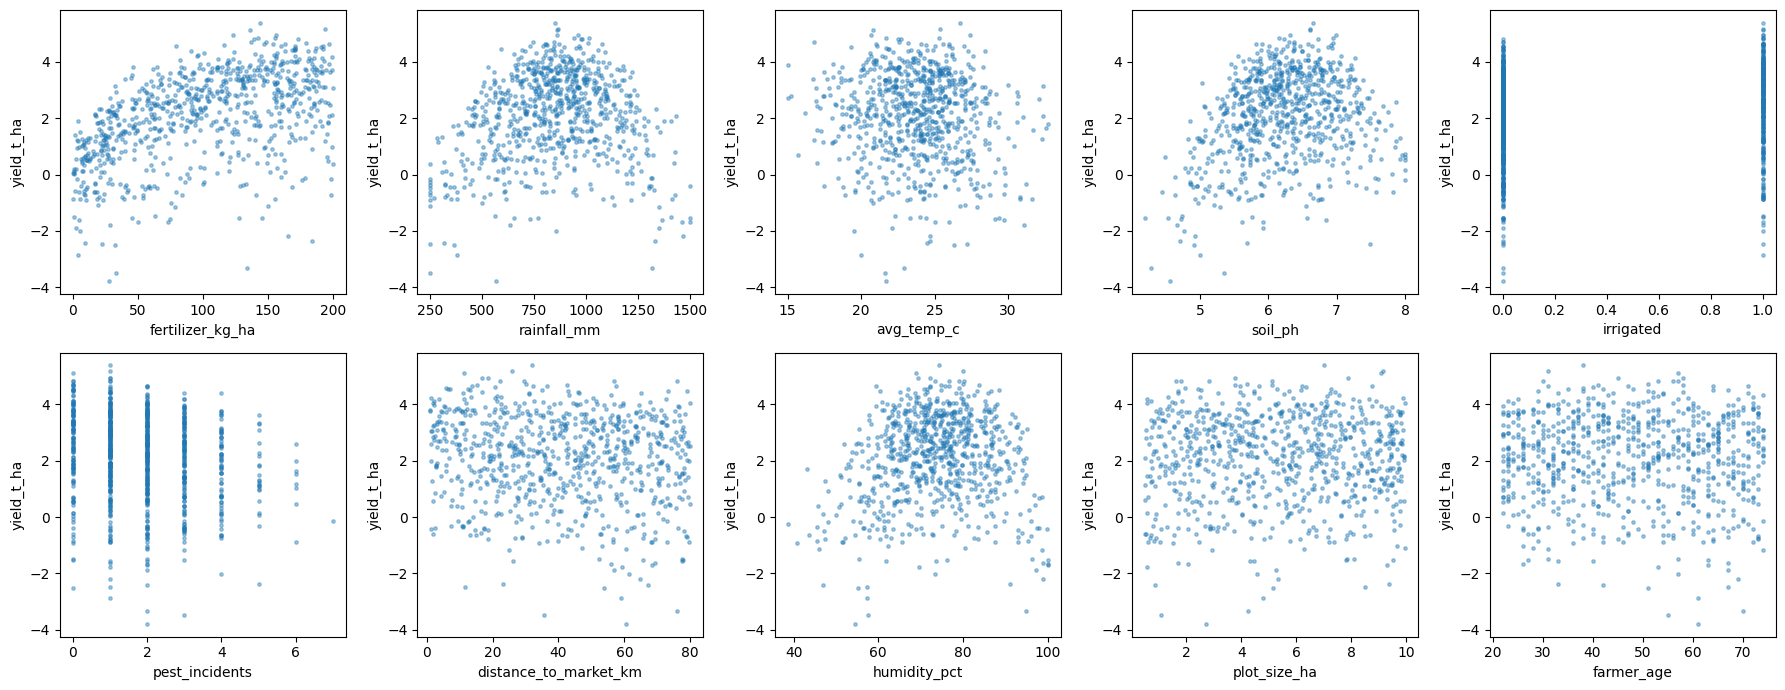

In [8]:
# Yield vs each feature
feature_names = [c for c in df.columns if c != "yield_t_ha"]
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), feature_names):
    ax.scatter(df[col], df["yield_t_ha"], s=6, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("yield_t_ha")
plt.tight_layout()
plt.show()

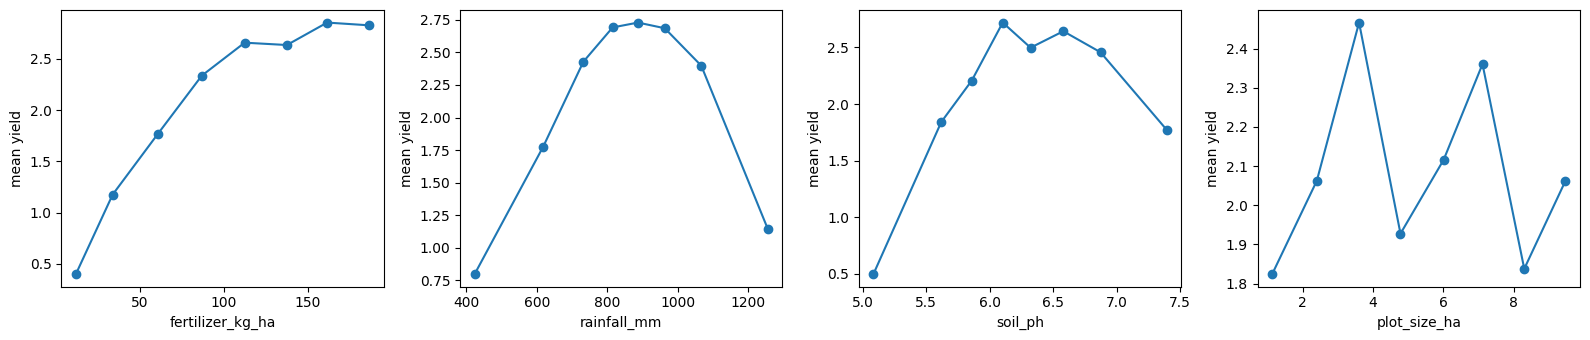

In [9]:
# Average yield in 8 equal-sized bins: curves show up clearly
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["fertilizer_kg_ha", "rainfall_mm", "soil_ph", "plot_size_ha"]):
    bins = pd.qcut(df[col], 8)
    means = df.groupby(bins, observed=True)["yield_t_ha"].mean()
    centers = df.groupby(bins, observed=True)[col].mean()
    ax.plot(centers, means, "o-")
    ax.set_xlabel(col)
    ax.set_ylabel("mean yield")
plt.tight_layout()
plt.show()

**What to notice**
- Fertilizer: yield rises but flattens (diminishing returns).
- Rainfall and soil pH: yield rises then falls (a best level), so a straight line fits badly.
- Plot size (and farmer age): flat, no effect.
- Rainfall and humidity: strongly correlated, so they overlap.

## 4. Train/test split and scoring setup

The 20% test set stays untouched until each model's final score. Cross-validation (CV) uses the training set only:
split it into 5 parts, train on 4, score on the 5th, rotate, average.

Metrics: **R²** (share of variance explained), **RMSE** (typical error in t/ha, punishes big misses), **MAE** (average error in t/ha).

In [10]:
# Load data (run notebook 01 first to create farm_yield.csv)
df = pd.read_csv("farm_yield.csv")
features = [c for c in df.columns if c != "yield_t_ha"]
X = df[features]
y = df["yield_t_ha"]

# 80/20 split, same seed in every notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
cv = KFold(n_splits=5, shuffle=True, random_state=0)
print("train:", X_train.shape, "test:", X_test.shape)

train: (640, 10) test: (160, 10)


In [11]:
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

rows = []   # each model adds one row of results here

## 5. SLR: Simple Linear Regression

One input, one straight line: `yield = a + b * fertilizer`. The baseline: what can a single variable explain?

In [12]:
cols = ["fertilizer_kg_ha"]   # one feature only
model = LinearRegression()

In [13]:
# 5-fold CV on the training set
cv_scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=scoring)

# Fit on all training data, then score once on the test set
model.fit(X_train[cols], y_train)
pred = model.predict(X_test[cols])

row = {
    "model": "SLR",
    "cv_r2": cv_scores["test_r2"].mean(),
    "cv_rmse": -cv_scores["test_rmse"].mean(),
    "cv_mae": -cv_scores["test_mae"].mean(),
    "test_r2": r2_score(y_test, pred),
    "test_rmse": np.sqrt(mean_squared_error(y_test, pred)),
    "test_mae": mean_absolute_error(y_test, pred),
}
rows.append(row)
pd.DataFrame([row]).round(3)

,model,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
0,SLR,0.187,1.377,1.075,0.316,1.252,0.992


intercept: 0.742
slope (t/ha per kg fertilizer): 0.0132


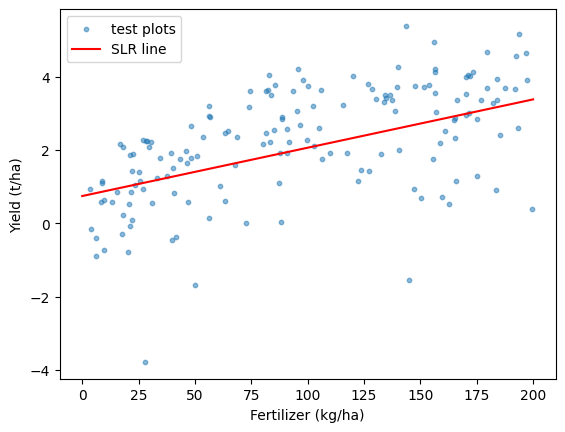

In [14]:
# The fitted line: yield = intercept + slope * fertilizer
print("intercept:", round(model.intercept_, 3))
print("slope (t/ha per kg fertilizer):", round(model.coef_[0], 4))

# The line through the test data
plt.scatter(X_test["fertilizer_kg_ha"], y_test, s=10, alpha=0.5, label="test plots")
grid = pd.DataFrame({"fertilizer_kg_ha": np.linspace(0, 200, 100)})
plt.plot(grid, model.predict(grid), "r", label="SLR line")
plt.xlabel("Fertilizer (kg/ha)")
plt.ylabel("Yield (t/ha)")
plt.legend()
plt.show()

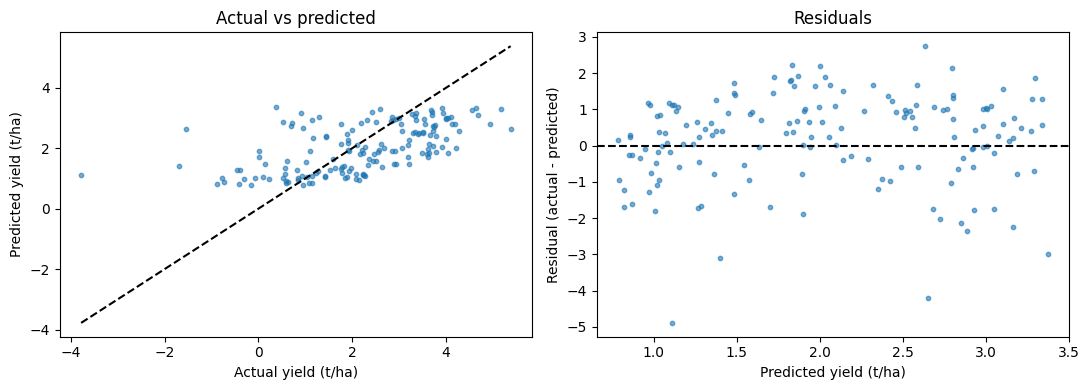

In [15]:
# Actual vs predicted, and residuals (test set)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(y_test, pred, s=10, alpha=0.6)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")  # perfect fit
ax[0].set_xlabel("Actual yield (t/ha)")
ax[0].set_ylabel("Predicted yield (t/ha)")
ax[0].set_title("Actual vs predicted")

ax[1].scatter(pred, y_test - pred, s=10, alpha=0.6)
ax[1].axhline(0, color="k", ls="--")
ax[1].set_xlabel("Predicted yield (t/ha)")
ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals")

plt.tight_layout()
plt.show()

## 6. MLR: Multiple Linear Regression

Every feature gets its own weight: `yield = a + b1*fertilizer + b2*rainfall + ...`.
All variables are used, but every effect is still a straight line, so it cannot bend around an optimum.
Features are standardized first so coefficients can be compared fairly.

In [16]:
cols = features
model = make_pipeline(StandardScaler(), LinearRegression())

In [17]:
# 5-fold CV on the training set
cv_scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=scoring)

# Fit on all training data, then score once on the test set
model.fit(X_train[cols], y_train)
pred = model.predict(X_test[cols])

row = {
    "model": "MLR",
    "cv_r2": cv_scores["test_r2"].mean(),
    "cv_rmse": -cv_scores["test_rmse"].mean(),
    "cv_mae": -cv_scores["test_mae"].mean(),
    "test_r2": r2_score(y_test, pred),
    "test_rmse": np.sqrt(mean_squared_error(y_test, pred)),
    "test_mae": mean_absolute_error(y_test, pred),
}
rows.append(row)
pd.DataFrame([row]).round(3)

,model,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
0,MLR,0.339,1.247,0.974,0.447,1.126,0.891


fertilizer_kg_ha         0.751
soil_ph                  0.422
pest_incidents          -0.282
irrigated                0.260
rainfall_mm              0.178
distance_to_market_km   -0.163
avg_temp_c              -0.139
humidity_pct            -0.080
farmer_age              -0.055
plot_size_ha             0.030
dtype: float64


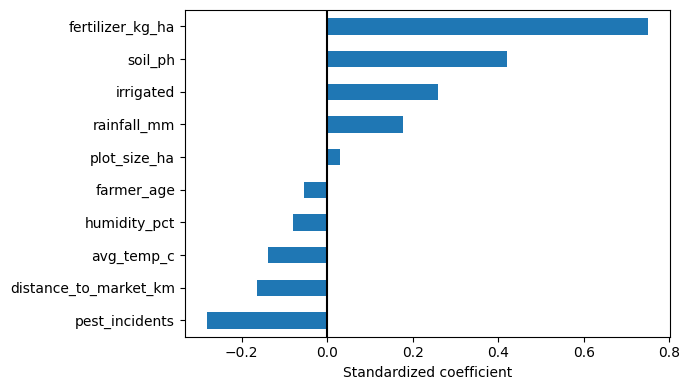

In [18]:
# Standardized coefficients: bigger absolute value = stronger straight-line effect
coefs = pd.Series(model[-1].coef_, index=features).sort_values(key=abs, ascending=False)
print(coefs.round(3))

coefs.sort_values().plot(kind="barh", figsize=(7, 4))
plt.axvline(0, color="k")
plt.xlabel("Standardized coefficient")
plt.tight_layout()
plt.show()

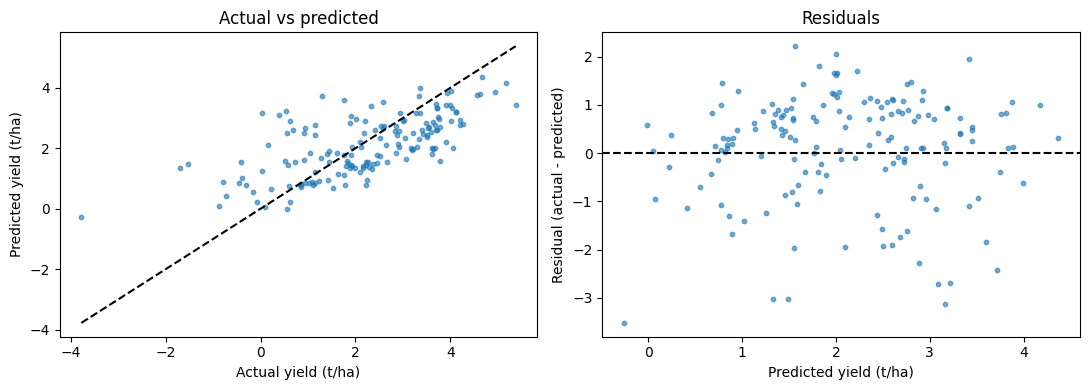

In [19]:
# Actual vs predicted, and residuals (test set)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(y_test, pred, s=10, alpha=0.6)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")  # perfect fit
ax[0].set_xlabel("Actual yield (t/ha)")
ax[0].set_ylabel("Predicted yield (t/ha)")
ax[0].set_title("Actual vs predicted")

ax[1].scatter(pred, y_test - pred, s=10, alpha=0.6)
ax[1].axhline(0, color="k", ls="--")
ax[1].set_xlabel("Predicted yield (t/ha)")
ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals")

plt.tight_layout()
plt.show()

A curved pattern in the residual plot (instead of a random cloud around 0) means the model is missing a nonlinear effect.

## 7. Polynomial Regression (degree 2)

MLR plus squared terms (like `rainfall²`) and pairwise products (like `fertilizer × rainfall`).
Squared terms let the model bend into arches and flatten out, which matches the hidden truth.

Risk: 10 features become 65 columns for only 640 training rows, so it can overfit. Compare train and test R².

In [20]:
# Scale -> add squares and products -> linear regression
cols = features
model = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), LinearRegression())

In [21]:
# 5-fold CV on the training set
cv_scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=scoring)

# Fit on all training data, then score once on the test set
model.fit(X_train[cols], y_train)
pred = model.predict(X_test[cols])

row = {
    "model": "Polynomial",
    "cv_r2": cv_scores["test_r2"].mean(),
    "cv_rmse": -cv_scores["test_rmse"].mean(),
    "cv_mae": -cv_scores["test_mae"].mean(),
    "test_r2": r2_score(y_test, pred),
    "test_rmse": np.sqrt(mean_squared_error(y_test, pred)),
    "test_mae": mean_absolute_error(y_test, pred),
}
rows.append(row)
pd.DataFrame([row]).round(3)

,model,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
0,Polynomial,0.933,0.394,0.314,0.928,0.405,0.312


In [22]:
# Overfitting check: a big gap between train and test R2 is a warning sign
print("columns created:", model.named_steps["polynomialfeatures"].n_output_features_)
print("train R2:", round(r2_score(y_train, model.predict(X_train)), 3))
print("test R2: ", round(r2_score(y_test, pred), 3))

columns created: 65
train R2: 0.95
test R2:  0.928


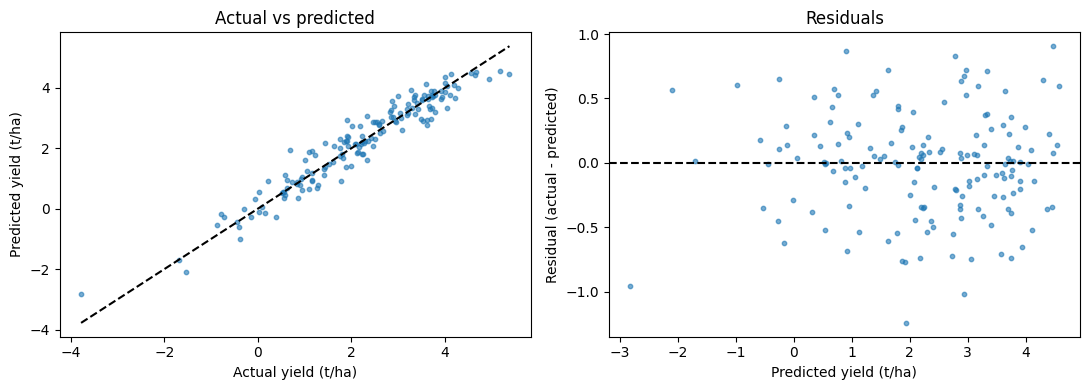

In [23]:
# Actual vs predicted, and residuals (test set)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(y_test, pred, s=10, alpha=0.6)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")  # perfect fit
ax[0].set_xlabel("Actual yield (t/ha)")
ax[0].set_ylabel("Predicted yield (t/ha)")
ax[0].set_title("Actual vs predicted")

ax[1].scatter(pred, y_test - pred, s=10, alpha=0.6)
ax[1].axhline(0, color="k", ls="--")
ax[1].set_xlabel("Predicted yield (t/ha)")
ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals")

plt.tight_layout()
plt.show()

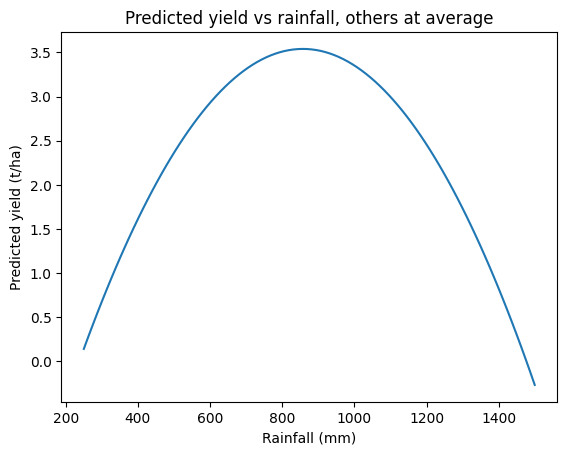

In [24]:
# Rainfall effect with all other features at their average (shows the arch)
avg = X_train.mean()
grid = pd.DataFrame([avg] * 100)
grid["rainfall_mm"] = np.linspace(250, 1500, 100)
plt.plot(grid["rainfall_mm"], model.predict(grid))
plt.xlabel("Rainfall (mm)")
plt.ylabel("Predicted yield (t/ha)")
plt.title("Predicted yield vs rainfall, others at average")
plt.show()

## 8. Ridge Regression (polynomial degree 2 + L2 penalty)

The degree-2 polynomial with a penalty on large coefficients. Large coefficients suggest the model is chasing noise,
so Ridge shrinks them toward zero (never exactly to zero).

**alpha** sets the penalty strength: near 0 = plain polynomial, large = heavy shrinking.
First a fixed alpha (10), then the best alpha picked by CV on the training set.

In [25]:
# Ridge with fixed alpha = 10
cols = features
model = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=10))

In [26]:
# 5-fold CV on the training set
cv_scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=scoring)

# Fit on all training data, then score once on the test set
model.fit(X_train[cols], y_train)
pred = model.predict(X_test[cols])

row = {
    "model": "Ridge (alpha=10)",
    "cv_r2": cv_scores["test_r2"].mean(),
    "cv_rmse": -cv_scores["test_rmse"].mean(),
    "cv_mae": -cv_scores["test_mae"].mean(),
    "test_r2": r2_score(y_test, pred),
    "test_rmse": np.sqrt(mean_squared_error(y_test, pred)),
    "test_mae": mean_absolute_error(y_test, pred),
}
rows.append(row)
pd.DataFrame([row]).round(3)

,model,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
0,Ridge (alpha=10),0.933,0.392,0.314,0.929,0.403,0.312


best alpha: 9.541  CV R2: 0.933


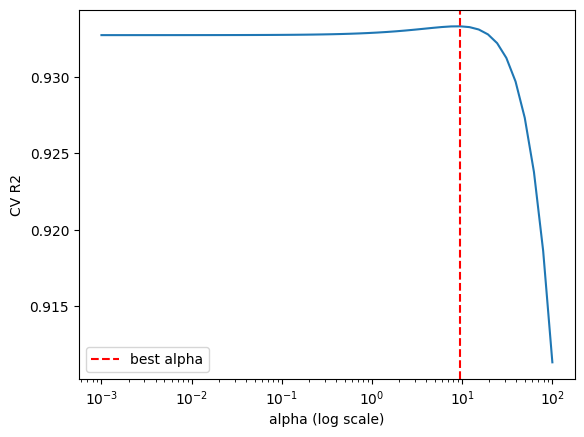

In [27]:
# Tune alpha: 50 values from 0.001 to 100, CV on the training set only
alphas = np.logspace(-3, 2, 50)
search = GridSearchCV(
    make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge()),
    {"ridge__alpha": alphas}, cv=cv, scoring="r2"
).fit(X_train, y_train)

best_alpha = search.best_params_["ridge__alpha"]
print("best alpha:", round(best_alpha, 3), " CV R2:", round(search.best_score_, 3))

# CV score vs alpha
plt.semilogx(alphas, search.cv_results_["mean_test_score"])
plt.axvline(best_alpha, color="r", ls="--", label="best alpha")
plt.xlabel("alpha (log scale)")
plt.ylabel("CV R2")
plt.legend()
plt.show()

In [28]:
model = search.best_estimator_   # already refit on the full training set

# 5-fold CV on the training set
cv_scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=scoring)

# Fit on all training data, then score once on the test set
model.fit(X_train[cols], y_train)
pred = model.predict(X_test[cols])

row = {
    "model": "Ridge (tuned)",
    "cv_r2": cv_scores["test_r2"].mean(),
    "cv_rmse": -cv_scores["test_rmse"].mean(),
    "cv_mae": -cv_scores["test_mae"].mean(),
    "test_r2": r2_score(y_test, pred),
    "test_rmse": np.sqrt(mean_squared_error(y_test, pred)),
    "test_mae": mean_absolute_error(y_test, pred),
}
rows.append(row)
pd.DataFrame([row]).round(3)

,model,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
0,Ridge (tuned),0.933,0.392,0.314,0.929,0.403,0.312


The tuned alpha was picked using these same folds, so the CV score is slightly optimistic. The test set is used only for the final score.

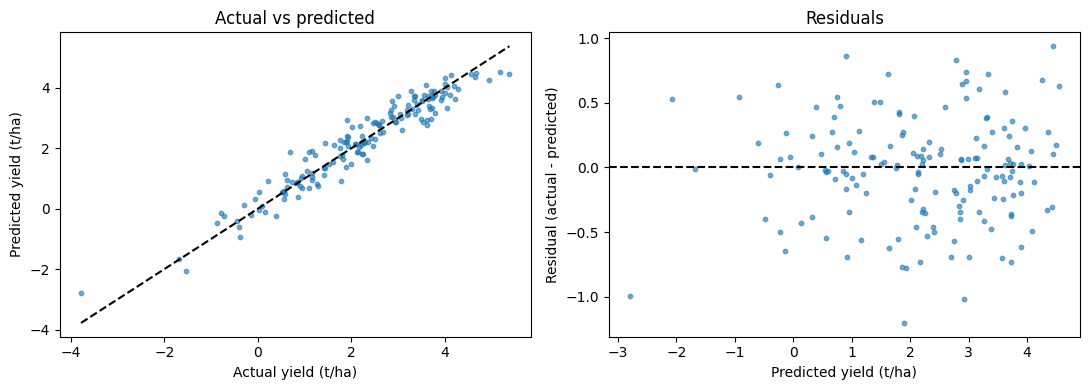

In [29]:
# Actual vs predicted, and residuals (test set)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(y_test, pred, s=10, alpha=0.6)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")  # perfect fit
ax[0].set_xlabel("Actual yield (t/ha)")
ax[0].set_ylabel("Predicted yield (t/ha)")
ax[0].set_title("Actual vs predicted")

ax[1].scatter(pred, y_test - pred, s=10, alpha=0.6)
ax[1].axhline(0, color="k", ls="--")
ax[1].set_xlabel("Predicted yield (t/ha)")
ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals")

plt.tight_layout()
plt.show()

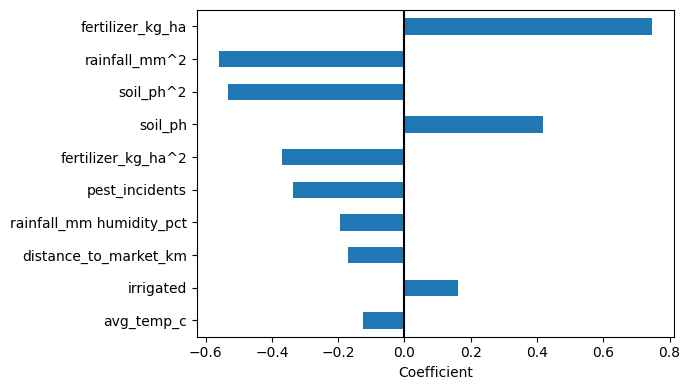

In [30]:
# 10 largest coefficients
names = model.named_steps["polynomialfeatures"].get_feature_names_out(features)
coefs = pd.Series(model[-1].coef_, index=names)
coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:10][::-1].plot(kind="barh", figsize=(7, 4))
plt.axvline(0, color="k")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

## 9. Lasso Regression (polynomial degree 2 + L1 penalty)

The degree-2 polynomial with a penalty that can shrink coefficients **exactly to zero**. A coefficient of 0 means that term is switched off,
so Lasso also selects features. Same plan as Ridge: fixed alpha (0.01), then tuned alpha.

In [31]:
# Lasso with fixed alpha = 0.01
cols = features
model = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Lasso(alpha=0.01, max_iter=50000))

In [32]:
# 5-fold CV on the training set
cv_scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=scoring)

# Fit on all training data, then score once on the test set
model.fit(X_train[cols], y_train)
pred = model.predict(X_test[cols])

row = {
    "model": "Lasso (alpha=0.01)",
    "cv_r2": cv_scores["test_r2"].mean(),
    "cv_rmse": -cv_scores["test_rmse"].mean(),
    "cv_mae": -cv_scores["test_mae"].mean(),
    "test_r2": r2_score(y_test, pred),
    "test_rmse": np.sqrt(mean_squared_error(y_test, pred)),
    "test_mae": mean_absolute_error(y_test, pred),
}
rows.append(row)
pd.DataFrame([row]).round(3)

,model,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
0,Lasso (alpha=0.01),0.938,0.379,0.303,0.932,0.394,0.308


best alpha: 0.0133  CV R2: 0.938


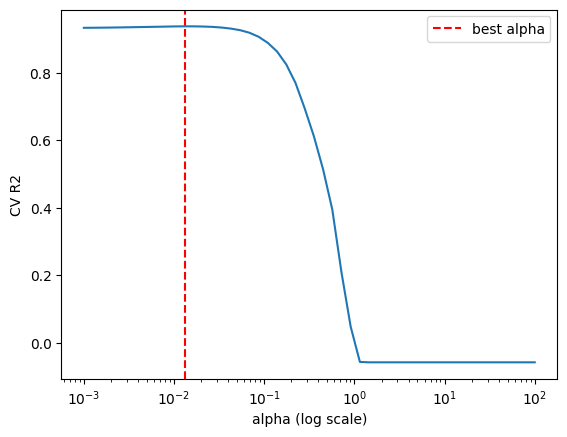

In [33]:
# Tune alpha: 50 values from 0.001 to 100, CV on the training set only
alphas = np.logspace(-3, 2, 50)
search = GridSearchCV(
    make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Lasso(max_iter=50000)),
    {"lasso__alpha": alphas}, cv=cv, scoring="r2"
).fit(X_train, y_train)

best_alpha = search.best_params_["lasso__alpha"]
print("best alpha:", round(best_alpha, 4), " CV R2:", round(search.best_score_, 3))

# CV score vs alpha
plt.semilogx(alphas, search.cv_results_["mean_test_score"])
plt.axvline(best_alpha, color="r", ls="--", label="best alpha")
plt.xlabel("alpha (log scale)")
plt.ylabel("CV R2")
plt.legend()
plt.show()

In [34]:
model = search.best_estimator_   # already refit on the full training set

# 5-fold CV on the training set
cv_scores = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=scoring)

# Fit on all training data, then score once on the test set
model.fit(X_train[cols], y_train)
pred = model.predict(X_test[cols])

row = {
    "model": "Lasso (tuned)",
    "cv_r2": cv_scores["test_r2"].mean(),
    "cv_rmse": -cv_scores["test_rmse"].mean(),
    "cv_mae": -cv_scores["test_mae"].mean(),
    "test_r2": r2_score(y_test, pred),
    "test_rmse": np.sqrt(mean_squared_error(y_test, pred)),
    "test_mae": mean_absolute_error(y_test, pred),
}
rows.append(row)
pd.DataFrame([row]).round(3)

,model,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
0,Lasso (tuned),0.938,0.377,0.302,0.932,0.393,0.308


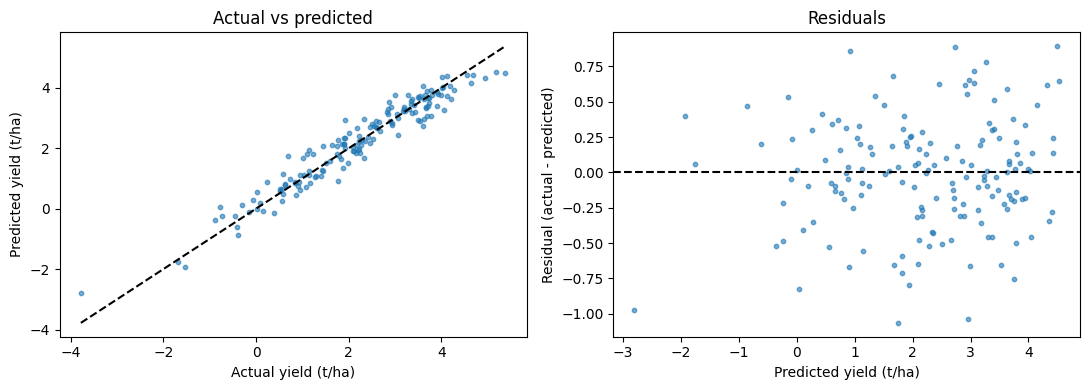

In [35]:
# Actual vs predicted, and residuals (test set)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(y_test, pred, s=10, alpha=0.6)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--")  # perfect fit
ax[0].set_xlabel("Actual yield (t/ha)")
ax[0].set_ylabel("Predicted yield (t/ha)")
ax[0].set_title("Actual vs predicted")

ax[1].scatter(pred, y_test - pred, s=10, alpha=0.6)
ax[1].axhline(0, color="k", ls="--")
ax[1].set_xlabel("Predicted yield (t/ha)")
ax[1].set_ylabel("Residual (actual - predicted)")
ax[1].set_title("Residuals")

plt.tight_layout()
plt.show()

kept: 27  switched off: 38  of 65
fertilizer_kg_ha         0.748
rainfall_mm^2           -0.655
soil_ph^2               -0.526
soil_ph                  0.414
fertilizer_kg_ha^2      -0.361
pest_incidents          -0.327
irrigated                0.235
distance_to_market_km   -0.163
avg_temp_c              -0.110
avg_temp_c^2            -0.063
dtype: float64


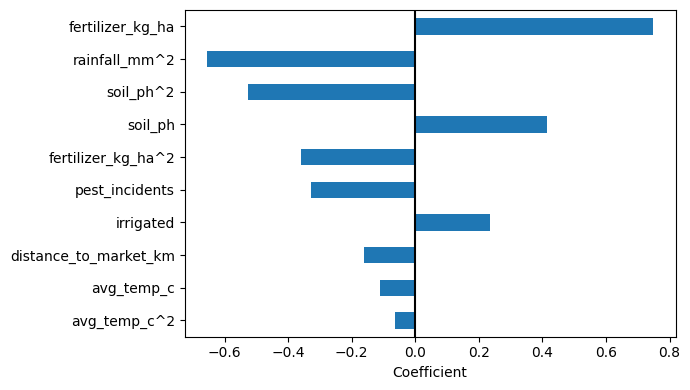

In [36]:
# Which polynomial terms survive?
names = model.named_steps["polynomialfeatures"].get_feature_names_out(features)
coefs = pd.Series(model[-1].coef_, index=names)
print("kept:", (coefs != 0).sum(), " switched off:", (coefs == 0).sum(), " of", len(coefs))

# 10 largest terms
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:10]
print(top.round(3))
top[::-1].plot(kind="barh", figsize=(7, 4))
plt.axvline(0, color="k")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

### Interpret Lasso on the original features

Squared terms and products make the table above hard to read. Here Lasso is fit on the 10 original columns (standardized)
to see which features survive and which get switched off. Each coefficient is the straight-line part of that feature's effect.

In [37]:
# Lasso on the plain features, alpha chosen by CV
lasso_lin = make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=cv, max_iter=20000))
lasso_lin.fit(X_train, y_train)
print("alpha chosen:", round(lasso_lin[-1].alpha_, 4))

lin = pd.DataFrame({"coefficient": lasso_lin[-1].coef_}, index=features)

# Exactly 0 = switched off; tiny = effectively off
lin["verdict"] = "kept"
lin.loc[lin["coefficient"].abs() < 0.05, "verdict"] = "near zero"
lin.loc[lin["coefficient"] == 0, "verdict"] = "switched off"

lin = lin.reindex(lin["coefficient"].abs().sort_values(ascending=False).index)
lin.round(3)

alpha chosen: 0.0133


,coefficient,verdict
fertilizer_kg_ha,0.739,kept
soil_ph,0.408,kept
pest_incidents,-0.269,kept
irrigated,0.248,kept
distance_to_market_km,-0.151,kept
avg_temp_c,-0.125,kept
rainfall_mm,0.095,kept
farmer_age,-0.044,near zero
plot_size_ha,0.017,near zero
humidity_pct,-0.000,switched off


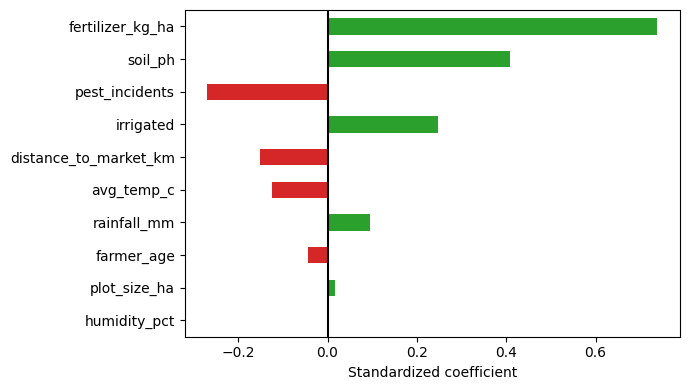

In [38]:
# Bar chart of the coefficients
colors = ["tab:green" if c > 0 else "tab:red" for c in lin["coefficient"][::-1]]
lin["coefficient"][::-1].plot(kind="barh", color=colors, figsize=(7, 4))
plt.axvline(0, color="k")
plt.xlabel("Standardized coefficient")
plt.tight_layout()
plt.show()

**How to read this**
- Large coefficients (fertilizer, soil pH, pests, irrigation) are the strongest straight-line effects.
- `humidity_pct` is switched off: it duplicates rainfall.
- `plot_size_ha` and `farmer_age` are at or near zero: no real effect.
- `soil_ph` and `rainfall_mm` have curved effects (best near 6.5 and 850 mm), so one slope understates them. The squared terms in the polynomial Lasso carry the rest.

## 10. Compare all models

In [39]:
results = pd.DataFrame(rows).set_index("model").round(3)
results

,cv_r2,cv_rmse,cv_mae,test_r2,test_rmse,test_mae
model,,,,,,
SLR,0.187,1.377,1.075,0.316,1.252,0.992
MLR,0.339,1.247,0.974,0.447,1.126,0.891
Polynomial,0.933,0.394,0.314,0.928,0.405,0.312
Ridge (alpha=10),0.933,0.392,0.314,0.929,0.403,0.312
Ridge (tuned),0.933,0.392,0.314,0.929,0.403,0.312
Lasso (alpha=0.01),0.938,0.379,0.303,0.932,0.394,0.308
Lasso (tuned),0.938,0.377,0.302,0.932,0.393,0.308


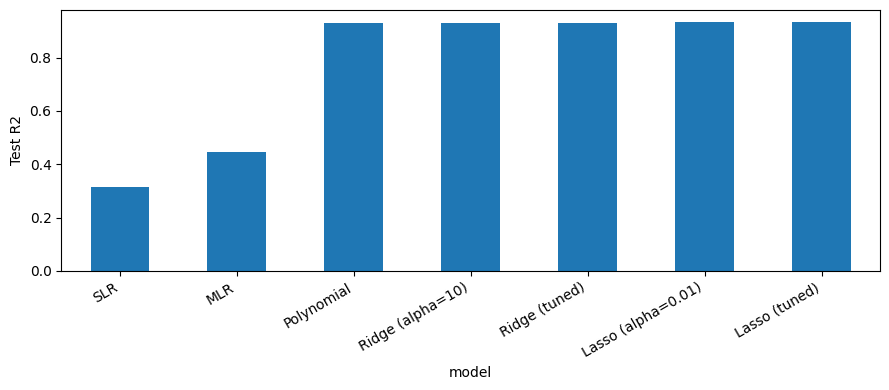

In [40]:
# Test R2 (higher is better)
results["test_r2"].plot(kind="bar", figsize=(9, 4))
plt.ylabel("Test R2")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

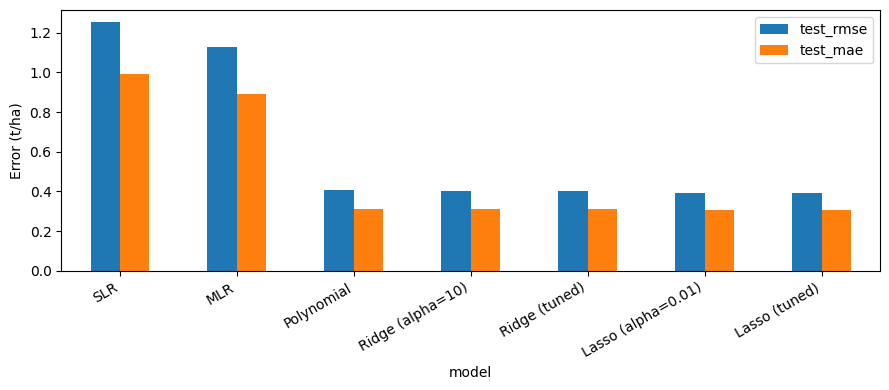

In [41]:
# Test errors in t/ha (lower is better)
results[["test_rmse", "test_mae"]].plot(kind="bar", figsize=(9, 4))
plt.ylabel("Error (t/ha)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

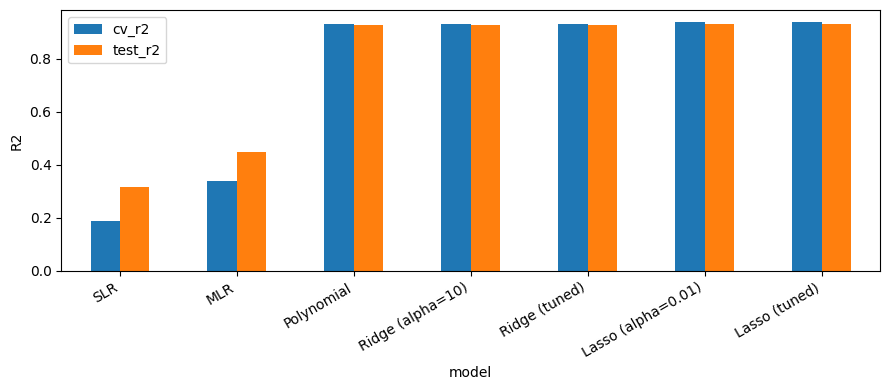

In [42]:
# CV R2 vs test R2: similar values mean the model generalises
results[["cv_r2", "test_r2"]].plot(kind="bar", figsize=(9, 4))
plt.ylabel("R2")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Reading the comparison**
- SLR and MLR are far behind: straight lines cannot follow the arch shapes.
- Polynomial, Ridge and Lasso are almost identical. The penalty adds only a small gain here (640 rows, 65 columns, mild overfitting), within the noise of one test split.

## 11. Memo to the Head of Agronomy (saved to memo.txt)

In [43]:
# Winner = lowest cross-validated RMSE
best_name = results["cv_rmse"].idxmin()
best = results.loc[best_name]
gain = best["test_r2"] - results.loc["Polynomial", "test_r2"]

# Top 4 drivers from the Lasso on the original features
top4 = lin.head(4)

notes = {
    "fertilizer_kg_ha": "more fertilizer raises yield, with diminishing returns",
    "soil_ph": "best near pH 6.5, lower or higher hurts",
    "rainfall_mm": "best near 850 mm, less or more hurts",
    "irrigated": "irrigated plots yield more",
    "pest_incidents": "each pest incident lowers yield",
    "avg_temp_c": "heat above 25 C lowers yield",
    "distance_to_market_km": "small drop with distance",
}
drivers = ""
for feature, r in top4.iterrows():
    drivers += f"- {feature} ({r['coefficient']:+.2f}): {notes.get(feature, '')}\n"

memo = f"""MEMO

To:      Head of Agronomy
From:    Data Science, Shamba Insights Ltd
Subject: Model for the maize yield forecast engine

DECISION
Use the {best_name} model (degree-2 polynomial) in the forecast engine.

WHY
On 160 plots it never saw, it explains {best['test_r2']*100:.0f}% of the variation in yield,
with a typical error of {best['test_mae']:.2f} t/ha (RMSE {best['test_rmse']:.2f}). The best straight-line model
(MLR) explains only {results.loc['MLR', 'test_r2']*100:.0f}%, and fertilizer alone (SLR) {results.loc['SLR', 'test_r2']*100:.0f}%. Rainfall
and soil pH each have a best level, and too little or too much lowers yield. A straight line
cannot follow that curve. Adding curves helped, not adding more variables. The penalty in
Ridge and Lasso added only {gain:.3f} R2 over plain polynomial, which is within the noise of one
test split, so this is not a big win. We still choose {best_name}: lowest cross-validated
error, and the penalty keeps the model stable if more features are added.

WHAT DRIVES YIELD (standardized Lasso coefficients, top 4)
{drivers}
WHERE IT BREAKS
- One season of data only. A very dry or wet year may fall outside what the model saw.
- The data is synthetic. Real farms will have effects not captured here.
- No soil-type variable, so soil differences are only partly explained.
- Reliable only inside the data range (fertilizer 0-200 kg/ha, rainfall 250-1500 mm).

NEXT STEP
Collect a second season and add soil texture, then test the model on that new season
before shipping.
"""

with open("memo.txt", "w", encoding="utf-8") as f:
    f.write(memo)

print(memo)

MEMO

To:      Head of Agronomy
From:    Data Science, Shamba Insights Ltd
Subject: Model for the maize yield forecast engine

DECISION
Use the Lasso (tuned) model (degree-2 polynomial) in the forecast engine.

WHY
On 160 plots it never saw, it explains 93% of the variation in yield,
with a typical error of 0.31 t/ha (RMSE 0.39). The best straight-line model
(MLR) explains only 45%, and fertilizer alone (SLR) 32%. Rainfall
and soil pH each have a best level, and too little or too much lowers yield. A straight line
cannot follow that curve. Adding curves helped, not adding more variables. The penalty in
Ridge and Lasso added only 0.004 R2 over plain polynomial, which is within the noise of one
test split, so this is not a big win. We still choose Lasso (tuned): lowest cross-validated
error, and the penalty keeps the model stable if more features are added.

WHAT DRIVES YIELD (standardized Lasso coefficients, top 4)
- fertilizer_kg_ha (+0.74): more fertilizer raises yield, with diminishi